<a href="https://colab.research.google.com/github/ProjetosGracie/SERS_GS26/blob/main/GS_SERS.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/Renato7373/GS_SERS/blob/main/GS_SERS.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ⚡ Citizen Assist AI — Módulo de Energia e Sustentabilidade
**Global Solution 2026 · Soluções em Energias Renováveis e Sustentáveis · FIAP · Ciência da Computação (1CCPJ)**

| Integrante | RM |
|---|---|
| Conrado Gracie | 569157 |
| Renato Sandreschi | 569156 |

> **Objetivo:** apoiar famílias de baixa renda a reduzir a conta de luz, comparando **eficiência energética**, **energia solar fotovoltaica** e a **combinação das duas**, e integrar os resultados ao assistente digital *Citizen Assist AI*, com dados, cálculos, referências, limitações e testes com usuários.

**Conteúdo**

1. Definição do contexto
2. Premissas e dados (origem, unidade, período, classificação)
3. Análise de consumo
4. Comparação das alternativas (custo, viabilidade e impacto ambiental)
5. Resumo executivo e recomendação
6. Integração ao assistente (respostas, referências e limitações)
7. Testes com usuários
8. Geração dos arquivos do repositório
9. Limitações e próximos passos

### Como este notebook atende ao enunciado

| Requisito técnico mínimo | Onde está neste notebook |
|---|---|
| Definição do contexto | Seção 1 |
| Análise de consumo (dados, unidades, período e premissas) | Seções 2 e 3 |
| Comparação de, no mínimo, duas alternativas (incluindo uma fonte renovável) | Seção 4 (A, B e C) |
| Integração ao assistente | Seção 6 (`responder()` + base de conhecimento exportada) |
| Referências e limitações | Seções 6 e 9 e arquivo `REFERENCIAS.md` |
| Testes com usuários | Seção 7 |
| Repositório organizado no GitHub | Seção 8 (gera README, dados, gráficos, testes e docs) |

> **Como executar:** *Ambiente de execução → Executar tudo*. Todas as células são independentes de arquivos externos e geram a pasta `citizen_assist_energia/`.

## 1. Definição do contexto

| Item | Descrição |
|---|---|
| **Público** | Famílias de baixa renda em moradias urbanas da Grande São Paulo (ex.: Santo André/SP), com 4 pessoas e ligação monofásica. A conta de energia é um dos maiores gastos fixos. |
| **Necessidade energética** | Reduzir o valor da conta de luz sem perder conforto, entendendo **onde a energia é gasta** e **o que compensa fazer primeiro**. |
| **Como o assistente ajuda** | Responde em linguagem simples: quanto cada aparelho gasta, quanto se economiza com cada medida, quanto custa, em quanto tempo se paga e quais são as limitações. |
| **Alternativas comparadas** | **A)** Eficiência energética e uso consciente (LED, banho, *stand-by*) · **B)** Energia solar fotovoltaica (fonte renovável) · **C)** Combinação A + B. |
| **Período de referência comum** | 1 mês (consumo e economia) e 25 anos (retorno financeiro). |

⚠️ **Todos os dados de consumo da residência são ESTIMADOS** (perfil típico), conforme permitido pelo enunciado, desde que identificados. Devem ser substituídos por dados reais do usuário (conta de luz) sempre que possível.

## 2. Premissas e dados (origem, unidade, período)

Cada dado recebe uma classificação:

| Classificação | Significado |
|---|---|
| `PÚBLICO` | Valor extraído de fonte pública verificável (a fonte é indicada). |
| `CALCULADO` | Derivado de dados públicos por uma conta explícita. |
| `ESTIMADO` | Estimativa justificada (faixa ou ordem de grandeza). |
| `HIPÓTESE` | Suposição de uso ou de projeto do perfil de família adotado. |

**Período de referência:** 1 mês (30 dias) e 25 anos · **Consulta às fontes:** 12/11/2026.

In [1]:
# ================= CONFIGURAÇÃO GERAL =================
import json
import os
import unicodedata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from IPython.display import display, Markdown

# Pasta onde o notebook gera os arquivos do repositório
PASTA = "citizen_assist_energia"
for subpasta in ["dados", "graficos", "testes", "docs"]:
    os.makedirs(f"{PASTA}/{subpasta}", exist_ok=True)

# Estilo padrão dos gráficos (visual limpo e consistente)
plt.rcParams.update({
    "figure.dpi": 110,
    "font.size": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
})

# Cores fixas para cada cenário (o mesmo cenário tem sempre a mesma cor)
COR_BASE = "#7f7f7f"
COR_DESTAQUE = "#c0392b"
CORES = {"A) Eficiência": "#2e8b57", "B) Solar": "#e0a100", "C) A + Solar": "#1f6fb2"}


# ---------- Funções de formatação (padrão brasileiro: 1.234,56) ----------
def numero(valor, casas=1):
    # Formata um número com vírgula decimal e ponto de milhar
    texto = f"{valor:,.{casas}f}"
    return texto.replace(",", "X").replace(".", ",").replace("X", ".")


def reais(valor, casas=2):
    # Formata um valor em reais: R$ 1.234,56
    return "R$ " + numero(valor, casas)


def formatar_tabela(df, casas=2):
    # Devolve uma cópia do DataFrame com os decimais no padrão brasileiro
    copia = df.copy()
    for coluna in copia.columns:
        if pd.api.types.is_float_dtype(copia[coluna]):
            copia[coluna] = copia[coluna].map(lambda v: "—" if pd.isna(v) else numero(v, casas))
    return copia


def salvar_grafico(nome):
    # Salva o gráfico atual na pasta do repositório (chamar ANTES de plt.show())
    plt.savefig(f"{PASTA}/graficos/{nome}.png", bbox_inches="tight", dpi=150)

In [2]:
# ================= PREMISSAS =================
# Legenda: [PÚBLICO] fonte verificável · [CALCULADO] conta explícita · [ESTIMADO] estimativa justificada · [HIPÓTESE] suposição do perfil
# Data da consulta às fontes: 12/11/2026

DIAS_MES = 30                      # [HIPÓTESE] período de referência mensal: 30 dias

# ---------- Tarifa de energia (R$/kWh, com tributos, TUSD + TE) ----------
TUSD_AGO25    = 0.55565            # [PÚBLICO] R$/kWh c/ tributos – fatura Enel SP (monofásica, 262 kWh, ago/2025)
TE_AGO25      = 0.37607            # [PÚBLICO] R$/kWh c/ tributos – mesma fatura
REAJ_ENEL26   = 0.1018             # [PÚBLICO] reajuste médio Enel SP, vigência 04/07/2026 (média de TODAS as classes; para residenciais B1 foi divulgado ~9,02%)
TARIFA        = round((TUSD_AGO25 + TE_AGO25) * (1 + REAJ_ENEL26), 2)   # [CALCULADO] ≈ R$ 1,03/kWh (sem bandeira tarifária)
CUSTO_DISP    = 30                 # [PÚBLICO] kWh/mês – mínimo faturável monofásico (REN ANEEL 1000/2021)

# ---------- Energia solar fotovoltaica ----------
HSP           = 4.3                # [ESTIMADO] kWh/m².dia (= horas de sol pleno). Faixa 4,1–4,6 na Grande SP. CONFIRMAR no SunData
PR            = 0.78               # [ESTIMADO] taxa de desempenho (perdas de inversor, temperatura, sujeira, cabos). Faixa típica 0,75–0,85
CUSTO_KWP     = 4500.0             # [ESTIMADO] R$/kWp instalado em sistema pequeno (~2 kWp). Sistemas menores têm R$/Wp maior que a média nacional
FIOB_PCT_2026 = 0.60               # [PÚBLICO] Lei 14.300/2022: em 2026 cobra-se 60% do "Fio B" sobre a energia injetada
FRAC_INJETADA = 0.70               # [HIPÓTESE] fração da geração injetada na rede (família fora de casa durante o dia)
FIOB_NA_TARIFA = 0.25              # [ESTIMADO] fração da tarifa correspondente ao Fio B
FATOR_COMP    = round(1 - FRAC_INJETADA * FIOB_NA_TARIFA * FIOB_PCT_2026, 3)   # [CALCULADO] fração da tarifa realmente economizada ≈ 0,90
DEGRADACAO    = 0.005              # [ESTIMADO] perda anual de geração (0,5% ao ano)
ANOS          = 25                 # [ESTIMADO] vida útil dos módulos (garantias típicas de 25 anos)
TROCA_INV_ANO = 12                 # [ESTIMADO] ano da troca do inversor
TROCA_INV_PCT = 0.12               # [ESTIMADO] custo da troca = 12% do investimento inicial
REAJUSTE_TAR  = 0.04               # [ESTIMADO] reajuste médio anual da tarifa (4% a.a., conservador frente aos reajustes recentes)

# ---------- Emissões (kg CO2e por kWh) ----------
FE_REDE       = 0.0385             # [PÚBLICO] fator médio anual do SIN em 2023 (MCTI): 0,0385 kgCO2/kWh
FE_FV_CICLO   = 0.041              # [ESTIMADO] ciclo de vida da solar em telhado ≈ 41 gCO2e/kWh (IPCC AR5, Anexo III, mediana)

# ---------- Medidas de eficiência (alternativa A) ----------
LED_W         = 9                  # [ESTIMADO] W – LED de 9 W substitui incandescente de 60 W (equivalência luminosa usual)
LED_CUSTO     = 8.0                # [ESTIMADO] R$ por lâmpada LED
STANDBY_NOVO  = 1                  # [ESTIMADO] W em stand-by após usar régua com interruptor
REGUA_CUSTO   = 40.0               # [ESTIMADO] R$ por régua com interruptor
REDUCAO_BANHO = 0.25               # [HIPÓTESE] banho de 8 min → 6 min (−25%)

# Parâmetros reunidos em um dicionário (exportado para o repositório)
PARAMETROS = {
    "DIAS_MES": DIAS_MES, "TARIFA": TARIFA, "CUSTO_DISP": CUSTO_DISP, "HSP": HSP, "PR": PR,
    "CUSTO_KWP": CUSTO_KWP, "FATOR_COMP": FATOR_COMP, "DEGRADACAO": DEGRADACAO,
    "REAJUSTE_TAR": REAJUSTE_TAR, "FE_REDE": FE_REDE, "FE_FV_CICLO": FE_FV_CICLO,
}

### Registro de dados e premissas
Tabela gerada automaticamente a partir das variáveis da célula anterior e exportada para `dados/premissas_origem.csv`.

In [3]:
premissas = pd.DataFrame([
    ["Tarifa (TUSD+TE, c/ tributos) ago/2025", TUSD_AGO25 + TE_AGO25, "R$/kWh", "ago/2025", "Fatura pública de unidade residencial monofásica da Enel SP (262 kWh) — camara.leg.br, cota parlamentar", "PÚBLICO"],
    ["Reajuste tarifário Enel SP 2026", REAJ_ENEL26 * 100, "%", "vigência 04/07/2026", "ANEEL — efeito médio de todas as classes (10,18%). Para residenciais B1 foi divulgado ~9,02% (ver REFERENCIAS.md); a sensibilidade cobre essa diferença", "PÚBLICO"],
    ["Tarifa adotada", TARIFA, "R$/kWh", "nov/2026 (sem bandeira)", "(TUSD+TE ago/2025) × (1 + reajuste 2026)", "CALCULADO"],
    ["Custo de disponibilidade monofásico", CUSTO_DISP, "kWh/mês", "vigente", "REN ANEEL 1000/2021; fatura pública de 30 kWh monofásico (Enel SP, jul/2025)", "PÚBLICO"],
    ["Irradiação / HSP", HSP, "kWh/m².dia (média anual)", "média anual", "Faixa 4,1–4,6 (material USP/AMT SP; SunData/CRESESB). Valor central escolhido; confirmar no SunData", "ESTIMADO"],
    ["Taxa de desempenho (PR)", PR, "adimensional", "média anual", "Faixa típica de projeto fotovoltaico (0,75–0,85)", "ESTIMADO"],
    ["Custo do sistema FV pequeno", CUSTO_KWP, "R$/kWp", "2025–2026", "Solfácil (R$ 2,45/Wp, média nacional 1T/2026), Greener (4 kWp = R$ 2,84/Wp, jun/2025), Monitor do Mercado (1,5–3 kWp = R$ 10–18 mil, 2026)", "ESTIMADO"],
    ["Fio B sobre energia injetada", FIOB_PCT_2026 * 100, "%", "2026", "Lei 14.300/2022 (escalonamento; 60% em 2026)", "PÚBLICO"],
    ["Fração injetada na rede", FRAC_INJETADA, "adimensional", "média anual", "Perfil: família ausente durante o dia", "HIPÓTESE"],
    ["Peso do Fio B na tarifa", FIOB_NA_TARIFA, "adimensional", "—", "Ordem de grandeza; conferir na conta/ANEEL da distribuidora", "ESTIMADO"],
    ["Fator de compensação", FATOR_COMP, "adimensional", "2026", "1 − fração injetada × peso do Fio B × 60%", "CALCULADO"],
    ["Degradação dos módulos", DEGRADACAO * 100, "% ao ano", "25 anos", "Valor típico de garantias de fabricantes", "ESTIMADO"],
    ["Reajuste anual da tarifa", REAJUSTE_TAR * 100, "% ao ano", "25 anos", "Premissa conservadora frente aos reajustes recentes da Enel SP (13,94% em 2025; 10,18% em 2026)", "ESTIMADO"],
    ["Fator de emissão do SIN", FE_REDE, "kgCO2/kWh", "média anual 2023", "MCTI (SIRENE) — 0,0385 tCO2/MWh", "PÚBLICO"],
    ["Emissão de ciclo de vida da solar", FE_FV_CICLO, "kgCO2e/kWh", "vida útil", "IPCC AR5 WGIII, Anexo III (mediana, solar de telhado)", "ESTIMADO"],
    ["Potências dos aparelhos", np.nan, "W", "—", "Faixas típicas Procel/INMETRO (tabela de potências); ver coluna 'origem' na tabela de consumo", "ESTIMADO"],
    ["Tempo de uso dos aparelhos", np.nan, "h/dia; dias/mês", "30 dias", "Hipóteses de uso de família de 4 pessoas (ex.: 4 banhos × 8 min, TV 5 h/dia)", "HIPÓTESE"],
], columns=["Parâmetro", "Valor", "Unidade", "Período/referência", "Origem / justificativa", "Classificação"])


def formatar_valor(v):
    # Mostra o valor sem zeros desnecessários (0,7800 -> 0,78 | 4.500,0000 -> 4.500)
    if pd.isna(v):
        return "—"
    return numero(v, 4).rstrip("0").rstrip(",")


# A tabela exibida usa texto formatado; o CSV exportado mantém o número original
premissas_exibicao = premissas.copy()
premissas_exibicao["Valor"] = premissas["Valor"].map(formatar_valor)
display(premissas_exibicao)

,Parâmetro,Valor,Unidade,Período/referência,Origem / justificativa,Classificação
0,"Tarifa (TUSD+TE, c/ tributos) ago/2025","0,9317",R$/kWh,ago/2025,Fatura pública de unidade residencial monofási...,PÚBLICO
1,Reajuste tarifário Enel SP 2026,"10,18",%,vigência 04/07/2026,"ANEEL — efeito médio de todas as classes (10,1...",PÚBLICO
2,Tarifa adotada,"1,03",R$/kWh,nov/2026 (sem bandeira),(TUSD+TE ago/2025) × (1 + reajuste 2026),CALCULADO
3,Custo de disponibilidade monofásico,30,kWh/mês,vigente,REN ANEEL 1000/2021; fatura pública de 30 kWh ...,PÚBLICO
4,Irradiação / HSP,"4,3",kWh/m².dia (média anual),média anual,"Faixa 4,1–4,6 (material USP/AMT SP; SunData/CR...",ESTIMADO
5,Taxa de desempenho (PR),"0,78",adimensional,média anual,"Faixa típica de projeto fotovoltaico (0,75–0,85)",ESTIMADO
6,Custo do sistema FV pequeno,4.500,R$/kWp,2025–2026,"Solfácil (R$ 2,45/Wp, média nacional 1T/2026),...",ESTIMADO
7,Fio B sobre energia injetada,60,%,2026,Lei 14.300/2022 (escalonamento; 60% em 2026),PÚBLICO
8,Fração injetada na rede,"0,7",adimensional,média anual,Perfil: família ausente durante o dia,HIPÓTESE
9,Peso do Fio B na tarifa,"0,25",adimensional,—,Ordem de grandeza; conferir na conta/ANEEL da ...,ESTIMADO


## 3. Análise de consumo

Perfil **estimado** de uma família de 4 pessoas. A energia de cada aparelho é calculada por:

$$E\ (\text{kWh}) = P\ (\text{kW}) \times t\ (\text{h})$$

No mês: `kWh/mês = potência (W) / 1000 × horas por dia × dias por mês × quantidade × fator de ciclo` (o *fator de ciclo* representa a fração do tempo em que o aparelho realmente consome, como o compressor da geladeira).

In [4]:
# Perfil de consumo ESTIMADO de uma família de 4 pessoas (potências típicas Procel/INMETRO; horas = hipóteses)
equip = pd.DataFrame([
    # nome, W, h/dia, dias/mês, qtd, fator_ciclo, tipo, origem
    ["Chuveiro elétrico (4 pessoas x 8 min)", 5500, 32/60, 30, 1, 1.0, "ESTIMADO", "Potência típica 4.400–7.700 W (tabela de potências, Procel/INMETRO); 4 banhos x 8 min = hipótese"],
    ["Geladeira antiga (compressor, ciclo 50%)", 150, 24, 30, 1, 0.5, "ESTIMADO", "Potência 100–400 W (Procel/INMETRO); compressor liga ~50% do tempo (hipótese para modelo antigo)"],
    ["Lâmpadas incandescentes 60 W", 60, 5, 30, 6, 1.0, "HIPÓTESE", "6 lâmpadas, 5 h/dia (hipótese de uso residencial)"],
    ["TV", 100, 5, 30, 1, 1.0, "ESTIMADO", "100 W, 5 h/dia (casa-modelo ValorFinal, com dados Procel)"],
    ["Ferro de passar", 1000, 1, 8, 1, 1.0, "ESTIMADO", "1.000–1.800 W (Procel/INMETRO); 8 h/mês"],
    ["Máquina de lavar", 500, 1, 12, 1, 1.0, "ESTIMADO", "500 W, 1 h por ciclo (tabela de potências); 12 ciclos/mês = hipótese"],
    ["Ventilador", 80, 6, 30, 1, 1.0, "HIPÓTESE", "80 W, 6 h/dia"],
    ["Roteador/Wi-Fi", 10, 24, 30, 1, 1.0, "HIPÓTESE", "10 W, ligado 24 h"],
    ["Stand-by (carregadores, TV, decoder)", 8, 24, 30, 1, 1.0, "HIPÓTESE", "8 W somados, 24 h"],
], columns=["equipamento", "potencia_W", "horas_dia", "dias_mes", "qtd", "fator_ciclo", "tipo", "origem"])


def kwh_mes(df):
    # Energia mensal de cada linha da tabela: E = P(kW) x t(h)
    return df["potencia_W"] / 1000 * df["horas_dia"] * df["dias_mes"] * df["qtd"] * df["fator_ciclo"]


equip["kWh_mes"] = kwh_mes(equip)
equip["R$_mes"] = equip["kWh_mes"] * TARIFA
equip["%"] = 100 * equip["kWh_mes"] / equip["kWh_mes"].sum()

CONSUMO_BASE = equip["kWh_mes"].sum()
CUSTO_BASE = CONSUMO_BASE * TARIFA

# Verificações simples de consistência dos dados
assert (equip["kWh_mes"] >= 0).all(), "Consumo negativo na tabela"
assert abs(equip["%"].sum() - 100) < 1e-9, "Os percentuais devem somar 100%"

# Tabela de apresentação (ordenada do maior para o menor consumo)
tabela_consumo = equip.sort_values("kWh_mes", ascending=False)[
    ["equipamento", "potencia_W", "horas_dia", "dias_mes", "qtd", "kWh_mes", "R$_mes", "%", "tipo"]
].reset_index(drop=True)
tabela_consumo.columns = ["Equipamento", "Potência (W)", "Horas/dia", "Dias/mês", "Qtd", "kWh/mês", "R$/mês", "% do total", "Classificação"]
display(formatar_tabela(tabela_consumo))

display(Markdown(
    f"**[ESTIMADO] Consumo total:** {numero(CONSUMO_BASE, 0)} kWh/mês · **Conta estimada:** {reais(CUSTO_BASE)}/mês "
    f"(tarifa {reais(TARIFA)}/kWh).  \n"
    "**Checagem de ordem de grandeza:** faturas públicas de residências monofásicas na área da Enel SP mostram ~218 a 262 kWh/mês (2025)."
))

,Equipamento,Potência (W),Horas/dia,Dias/mês,Qtd,kWh/mês,R$/mês,% do total,Classificação
0,Chuveiro elétrico (4 pessoas x 8 min),5500,"0,53",30,1,"88,00","90,64","34,87",ESTIMADO
1,Lâmpadas incandescentes 60 W,60,"5,00",30,6,"54,00","55,62","21,40",HIPÓTESE
2,"Geladeira antiga (compressor, ciclo 50%)",150,"24,00",30,1,"54,00","55,62","21,40",ESTIMADO
3,TV,100,"5,00",30,1,"15,00","15,45","5,94",ESTIMADO
4,Ventilador,80,"6,00",30,1,"14,40","14,83","5,71",HIPÓTESE
5,Ferro de passar,1000,"1,00",8,1,"8,00","8,24","3,17",ESTIMADO
6,Roteador/Wi-Fi,10,"24,00",30,1,"7,20","7,42","2,85",HIPÓTESE
7,Máquina de lavar,500,"1,00",12,1,"6,00","6,18","2,38",ESTIMADO
8,"Stand-by (carregadores, TV, decoder)",8,"24,00",30,1,"5,76","5,93","2,28",HIPÓTESE


**[ESTIMADO] Consumo total:** 252 kWh/mês · **Conta estimada:** R$ 259,93/mês (tarifa R$ 1,03/kWh).  
**Checagem de ordem de grandeza:** faturas públicas de residências monofásicas na área da Enel SP mostram ~218 a 262 kWh/mês (2025).

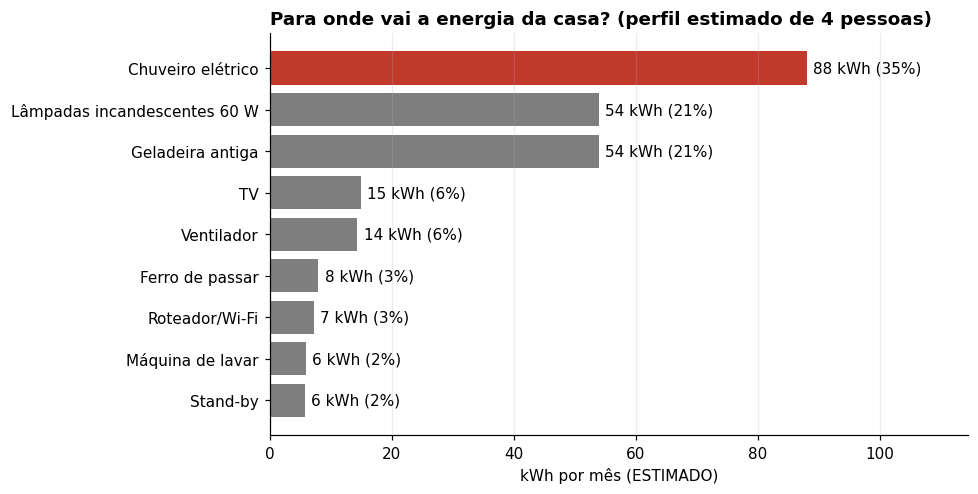

In [5]:
# Gráfico 1 — Para onde vai a energia da casa?
dados = equip.sort_values("kWh_mes")
nomes = [n.split("(")[0].strip() for n in dados["equipamento"]]
cores = [COR_DESTAQUE if k == dados["kWh_mes"].max() else COR_BASE for k in dados["kWh_mes"]]

fig, ax = plt.subplots(figsize=(9, 4.6))
barras = ax.barh(nomes, dados["kWh_mes"], color=cores)
for barra, pct in zip(barras, dados["%"]):
    ax.text(barra.get_width() + 1, barra.get_y() + barra.get_height() / 2,
            f"{numero(barra.get_width(), 0)} kWh ({numero(pct, 0)}%)", va="center")
ax.set_xlim(0, dados["kWh_mes"].max() * 1.3)
ax.set_xlabel("kWh por mês (ESTIMADO)")
ax.set_title("Para onde vai a energia da casa? (perfil estimado de 4 pessoas)", loc="left", fontweight="bold")
ax.grid(axis="y", visible=False)
plt.tight_layout()
salvar_grafico("consumo_por_equipamento")
plt.show()

## 4. Comparação das alternativas

Todas as alternativas atendem à **mesma necessidade** (reduzir a conta de luz da mesma casa) e usam o **mesmo período de referência** (1 mês e 25 anos).

**Fórmulas usadas**
- Energia: `E (kWh) = P (kW) × t (h)`
- Geração solar mensal: `E = kWp × HSP × PR × dias`
- Dimensionamento: `kWp = (consumo − custo de disponibilidade) / (HSP × PR × dias)`
- Economia mensal da solar: `kWh abatidos × tarifa × fator de compensação`
- Retorno (*payback*): ano em que o saldo acumulado do fluxo de caixa passa a ser ≥ 0.
- CO₂ evitado líquido: `kWh evitados × fator da rede − kWh gerados × emissão de ciclo de vida da solar`

In [6]:
# ---------- Funções de cálculo ----------
def dimensionar_kwp(consumo_kwh):
    # Potência (kWp) necessária para abater o consumo acima do custo de disponibilidade
    kwp = max(0.0, (consumo_kwh - CUSTO_DISP) / (HSP * PR * DIAS_MES))
    if kwp > 0:
        return round(kwp * 2) / 2      # arredonda para múltiplos de 0,5 kWp (aprox. módulos comerciais)
    return 0.0


def simular_solar(consumo_kwh):
    # Dimensiona o sistema e calcula geração, energia abatida, investimento e economia mensal
    kwp = dimensionar_kwp(consumo_kwh)
    geracao = kwp * HSP * PR * DIAS_MES
    abatido = min(geracao, max(0, consumo_kwh - CUSTO_DISP))
    return {
        "kwp": kwp,
        "geracao": geracao,
        "abatido": abatido,
        "invest": kwp * CUSTO_KWP,
        "econ_rs": abatido * TARIFA * FATOR_COMP,
    }


def fluxo_de_caixa(investimento, economia_mensal, degradacao=0.0, troca_inversor=False):
    # Saldo acumulado ano a ano e payback (em anos, com interpolação dentro do ano)
    saldo = []
    acumulado = -investimento
    payback = np.nan
    for ano in range(1, ANOS + 1):
        economia_ano = economia_mensal * 12 * (1 + REAJUSTE_TAR) ** (ano - 1) * (1 - degradacao) ** (ano - 1)
        acumulado += economia_ano
        if troca_inversor and ano == TROCA_INV_ANO:
            acumulado -= TROCA_INV_PCT * investimento
        saldo.append(acumulado)
        if np.isnan(payback) and acumulado >= 0:
            anterior = saldo[-2] if ano > 1 else -investimento
            payback = (ano - 1) + (-anterior) / (acumulado - anterior)
    return np.array(saldo), payback


def montar_cenario(consumo_final, investimento, economia_kwh, economia_rs, kwp, geracao, co2_ano, solar):
    # Reúne os resultados de um cenário em um dicionário
    if investimento > 0:
        saldo, payback = fluxo_de_caixa(investimento, economia_rs,
                                        degradacao=DEGRADACAO if solar else 0.0,
                                        troca_inversor=solar)
    else:
        saldo, payback = np.zeros(ANOS), np.nan
    return {
        "consumo_final": consumo_final, "invest": investimento, "econ_kwh": economia_kwh,
        "econ_rs": economia_rs, "kwp": kwp, "geracao": geracao, "co2_ano": co2_ano,
        "saldo": saldo, "saldo_final": saldo[-1], "pb": payback,
    }

In [7]:
# ---------- Alternativa A: eficiência e uso consciente ----------
equip_A = equip.copy()
e_chuveiro = equip_A["equipamento"].str.startswith("Chuveiro")
e_lampada = equip_A["equipamento"].str.startswith("Lâmpadas")
e_standby = equip_A["equipamento"].str.startswith("Stand-by")

equip_A.loc[e_chuveiro, "horas_dia"] *= (1 - REDUCAO_BANHO)    # banho 25% mais curto
equip_A.loc[e_lampada, "potencia_W"] = LED_W                   # incandescente -> LED
equip_A.loc[e_standby, "potencia_W"] = STANDBY_NOVO            # régua com interruptor

QTD_LAMPADAS = int(equip.loc[e_lampada, "qtd"].iloc[0])
CONSUMO_A = kwh_mes(equip_A).sum()
INVEST_A = QTD_LAMPADAS * LED_CUSTO + REGUA_CUSTO
ECON_KWH_A = CONSUMO_BASE - CONSUMO_A
ECON_RS_A = ECON_KWH_A * TARIFA

# ---------- Alternativas B e C: solar fotovoltaica ----------
SB = simular_solar(CONSUMO_BASE)    # B: solar dimensionada para o consumo atual
SC = simular_solar(CONSUMO_A)       # C: eficiência primeiro, solar menor depois

# CO2 evitado líquido (kg/ano) = evitado na rede − emitido no ciclo de vida da solar
co2_A = ECON_KWH_A * FE_REDE * 12
co2_B = SB["abatido"] * (FE_REDE - FE_FV_CICLO) * 12
co2_C = (ECON_KWH_A * FE_REDE + SC["abatido"] * (FE_REDE - FE_FV_CICLO)) * 12

CENARIOS = {
    "Situação atual": montar_cenario(CONSUMO_BASE, 0, 0, 0, 0, 0, 0, solar=False),
    "A) Eficiência": montar_cenario(CONSUMO_A, INVEST_A, ECON_KWH_A, ECON_RS_A, 0, 0, co2_A, solar=False),
    "B) Solar": montar_cenario(CONSUMO_BASE - SB["abatido"], SB["invest"], SB["abatido"], SB["econ_rs"],
                               SB["kwp"], SB["geracao"], co2_B, solar=True),
    "C) A + Solar": montar_cenario(CONSUMO_A - SC["abatido"], INVEST_A + SC["invest"], ECON_KWH_A + SC["abatido"],
                                   ECON_RS_A + SC["econ_rs"], SC["kwp"], SC["geracao"], co2_C, solar=True),
}

# Tabela comparativa (mesma necessidade, mesmo período de referência)
linhas = []
for nome, c in CENARIOS.items():
    linhas.append([nome, c["kwp"], c["consumo_final"], c["econ_kwh"], c["econ_rs"], c["invest"],
                   c["pb"], c["saldo_final"], c["co2_ano"]])

comp = pd.DataFrame(linhas, columns=[
    "Cenário", "kWp", "Consumo faturado (kWh/mês)", "Economia (kWh/mês)", "Economia (R$/mês)",
    "Investimento (R$)", "Payback (anos)", f"Saldo acumulado em {ANOS} anos (R$)", "CO2 evitado líquido (kg/ano)"])
display(formatar_tabela(comp))

,Cenário,kWp,Consumo faturado (kWh/mês),Economia (kWh/mês),Economia (R$/mês),Investimento (R$),Payback (anos),Saldo acumulado em 25 anos (R$),CO2 evitado líquido (kg/ano)
0,Situação atual,"0,00","252,36","0,00","0,00","0,00",—,"0,00","0,00"
1,A) Eficiência,"0,00","179,42","72,94","75,13","88,00","0,10","37.457,39","33,70"
2,B) Solar,"2,00","51,12","201,24","185,51","9.000,00","3,85","76.398,19","-6,04"
3,C) A + Solar,"1,50","30,00","222,36","212,87","6.838,00","2,60","91.572,72","29,22"


### Viabilidade: o que cada alternativa exige
Avaliação **qualitativa** da equipe, complementar aos números acima.

In [8]:
A, B, C = CENARIOS["A) Eficiência"], CENARIOS["B) Solar"], CENARIOS["C) A + Solar"]

viabilidade = pd.DataFrame({
    "Critério": ["Investimento inicial", "Pré-requisitos", "Quem decide", "Prazo para começar a economizar",
                 "Principais riscos", "Impacto ambiental líquido"],
    "A) Eficiência": [reais(A["invest"], 0), "Nenhum", "O próprio morador (mesmo sendo inquilino)", "Imediato (dias)",
                      "Baixo: depende de manter os hábitos", "Pequeno, mas positivo"],
    "B) Solar": [reais(B["invest"], 0), "Telhado adequado, aprovação da distribuidora, crédito ou capital",
                 "Proprietário do imóvel", "Semanas a meses (projeto e homologação)",
                 "Médio: custo real, regras da Lei 14.300, qualidade da instalação", "Próximo de zero (ver seção 5)"],
    "C) A + Solar": [reais(A["invest"] + SC["invest"], 0), "Os mesmos da solar, com sistema menor",
                     "Proprietário (solar) e morador (eficiência)", "Eficiência imediata; solar em semanas a meses",
                     "Médio, com investimento menor que o de B", "Pequeno, mas positivo"],
})
display(viabilidade.set_index("Critério"))

,A) Eficiência,B) Solar,C) A + Solar
Critério,,,
Investimento inicial,R$ 88,R$ 9.000,R$ 6.838
Pré-requisitos,Nenhum,"Telhado adequado, aprovação da distribuidora, ...","Os mesmos da solar, com sistema menor"
Quem decide,O próprio morador (mesmo sendo inquilino),Proprietário do imóvel,Proprietário (solar) e morador (eficiência)
Prazo para começar a economizar,Imediato (dias),Semanas a meses (projeto e homologação),Eficiência imediata; solar em semanas a meses
Principais riscos,Baixo: depende de manter os hábitos,"Médio: custo real, regras da Lei 14.300, quali...","Médio, com investimento menor que o de B"
Impacto ambiental líquido,"Pequeno, mas positivo",Próximo de zero (ver seção 5),"Pequeno, mas positivo"


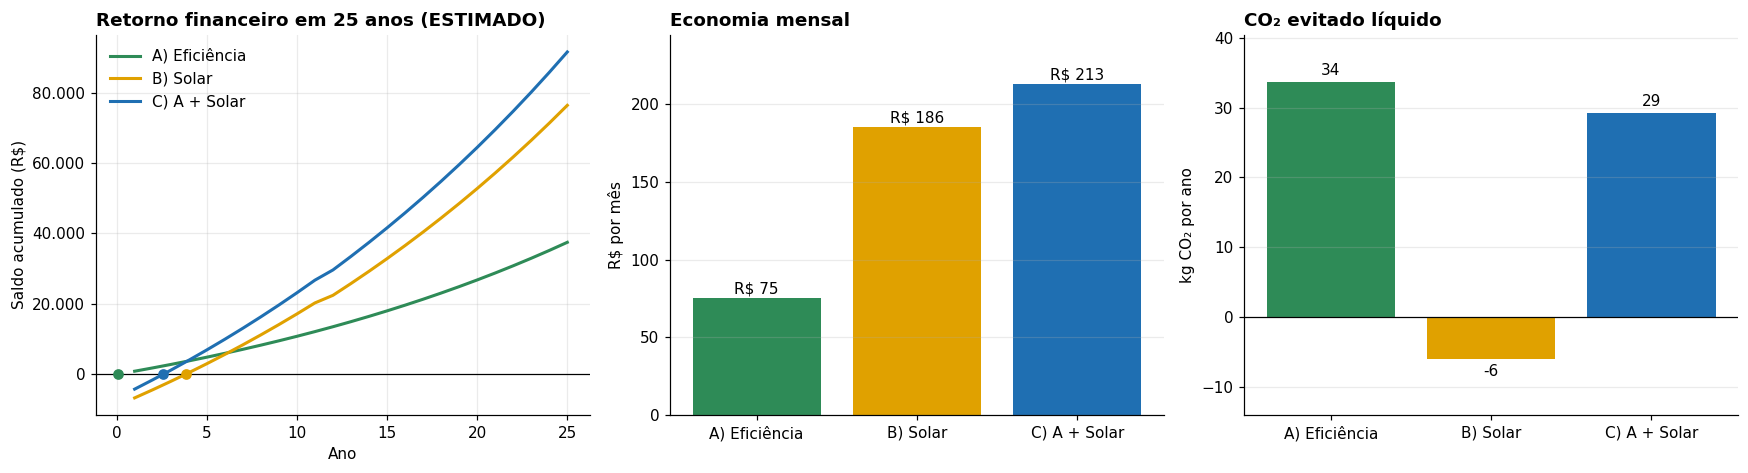

In [9]:
# Gráfico 2 — Comparação das alternativas
ordem = ["A) Eficiência", "B) Solar", "C) A + Solar"]
fig, ax = plt.subplots(1, 3, figsize=(16, 4.4))

# (a) Retorno financeiro acumulado
for nome in ordem:
    c = CENARIOS[nome]
    ax[0].plot(range(1, ANOS + 1), c["saldo"], label=nome, color=CORES[nome], lw=2)
    if not np.isnan(c["pb"]):
        ax[0].scatter([c["pb"]], [0], color=CORES[nome], zorder=5)
ax[0].axhline(0, color="k", lw=0.8)
ax[0].set_xlabel("Ano")
ax[0].set_ylabel("Saldo acumulado (R$)")
ax[0].yaxis.set_major_formatter(FuncFormatter(lambda v, _: numero(v, 0)))
ax[0].set_title("Retorno financeiro em 25 anos (ESTIMADO)", loc="left", fontweight="bold")
ax[0].legend(frameon=False)

# (b) Economia mensal
valores = [CENARIOS[n]["econ_rs"] for n in ordem]
barras = ax[1].bar(ordem, valores, color=[CORES[n] for n in ordem])
for barra, v in zip(barras, valores):
    ax[1].text(barra.get_x() + barra.get_width() / 2, v + 3, reais(v, 0), ha="center")
ax[1].set_ylim(0, max(valores) * 1.15)
ax[1].set_ylabel("R$ por mês")
ax[1].set_title("Economia mensal", loc="left", fontweight="bold")
ax[1].grid(axis="x", visible=False)

# (c) CO2 evitado líquido
valores = [CENARIOS[n]["co2_ano"] for n in ordem]
barras = ax[2].bar(ordem, valores, color=[CORES[n] for n in ordem])
for barra, v in zip(barras, valores):
    if v >= 0:
        ax[2].text(barra.get_x() + barra.get_width() / 2, v + 0.6, numero(v, 0), ha="center", va="bottom")
    else:
        ax[2].text(barra.get_x() + barra.get_width() / 2, v - 0.6, numero(v, 0), ha="center", va="top")
ax[2].set_ylim(min(valores) - 8, max(valores) * 1.2)
ax[2].axhline(0, color="k", lw=0.8)
ax[2].set_ylabel("kg CO₂ por ano")
ax[2].set_title("CO₂ evitado líquido", loc="left", fontweight="bold")
ax[2].grid(axis="x", visible=False)

plt.tight_layout()
salvar_grafico("comparacao_alternativas")
plt.show()

### Análise de sensibilidade
O resultado depende das premissas. A tabela mostra como o *payback* da solar (alternativa B) muda com a **tarifa** e o **custo por kWp**, as duas premissas de maior incerteza.

**Payback da solar (anos)** — “—” significa que não se paga em 25 anos.

,R$ 2.500/kWp,R$ 4.500/kWp,R$ 6.500/kWp
"Tarifa R$ 0,85","2,64","4,60","6,43"
"Tarifa R$ 1,03","2,20","3,85","5,40"
"Tarifa R$ 1,20","1,90","3,33","4,70"


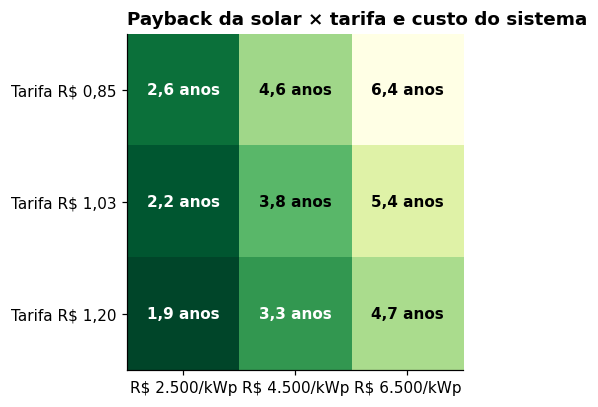

In [10]:
# Payback da solar (B) para diferentes tarifas (R$/kWh) e custos do sistema (R$/kWp)
tarifas = [0.85, TARIFA, 1.20]
custos = [2500, 4500, 6500]     # 2.500 = média nacional (Solfácil) | 6.500 = faixa alta para sistemas de 1,5–3 kWp

nomes_linhas = [f"Tarifa {reais(t)}" for t in tarifas]
nomes_colunas = [f"{reais(c, 0)}/kWp" for c in custos]
tab = pd.DataFrame(index=nomes_linhas, columns=nomes_colunas, dtype=float)

for i, t in enumerate(tarifas):
    for j, cst in enumerate(custos):
        invest = SB["kwp"] * cst
        economia = SB["abatido"] * t * FATOR_COMP
        _, pb = fluxo_de_caixa(invest, economia, degradacao=DEGRADACAO, troca_inversor=True)
        tab.iloc[i, j] = pb

display(Markdown("**Payback da solar (anos)** — “—” significa que não se paga em 25 anos."))
display(formatar_tabela(tab))

# Gráfico 3 — mapa de calor da sensibilidade
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.imshow(tab.values.astype(float), cmap="YlGn_r")
ax.set_xticks(range(len(nomes_colunas)))
ax.set_xticklabels(nomes_colunas)
ax.set_yticks(range(len(nomes_linhas)))
ax.set_yticklabels(nomes_linhas)
for i in range(len(tarifas)):
    for j in range(len(custos)):
        cor_texto = "white" if tab.iloc[i, j] < 3.5 else "black"      # texto claro sobre fundo escuro
        ax.text(j, i, f"{numero(tab.iloc[i, j], 1)} anos", ha="center", va="center", fontweight="bold", color=cor_texto)
ax.grid(False)
ax.set_title("Payback da solar × tarifa e custo do sistema", loc="left", fontweight="bold")
plt.tight_layout()
salvar_grafico("sensibilidade_payback")
plt.show()

## 5. Resumo executivo e recomendação

In [11]:
# Verificações: a narrativa abaixo só vale se estas relações forem verdadeiras
assert A["pb"] < C["pb"] < B["pb"], "A narrativa assume: payback A < C < B"
assert C["saldo_final"] > B["saldo_final"] > A["saldo_final"], "A narrativa assume: saldo C > B > A"

maior = equip.sort_values("kWh_mes").iloc[-1]
nome_maior = maior["equipamento"].split("(")[0].strip().lower()

RESUMO_CORPO = "\n".join([
    f"- **Diagnóstico (estimado):** a casa consome cerca de **{numero(CONSUMO_BASE, 0)} kWh/mês** (**{reais(CUSTO_BASE, 0)}/mês**). "
    f"O maior gasto é o {nome_maior}, com **{numero(maior['%'], 0)}%** do consumo.",
    f"- **A) Eficiência:** investimento de **{reais(A['invest'], 0)}**, economia de **{reais(A['econ_rs'], 0)}/mês** "
    f"({numero(A['econ_kwh'], 0)} kWh) e retorno em cerca de **{numero(A['pb'] * 12, 1)} meses**.",
    f"- **B) Solar:** sistema de **{numero(B['kwp'], 1)} kWp**, investimento de **{reais(B['invest'], 0)}**, economia de "
    f"**{reais(B['econ_rs'], 0)}/mês** e retorno em cerca de **{numero(B['pb'], 1)} anos**.",
    f"- **C) Eficiência + solar menor:** sistema de **{numero(C['kwp'], 1)} kWp**, investimento total de **{reais(C['invest'], 0)}**, "
    f"economia de **{reais(C['econ_rs'], 0)}/mês**, retorno em cerca de **{numero(C['pb'], 1)} anos** e o maior saldo em {ANOS} anos "
    f"(**{reais(C['saldo_final'], 0)}**).",
    "- **Recomendação:** começar pela eficiência (A), que é barata, rápida e não depende de ninguém; depois avaliar a solar "
    "dimensionada para o consumo já reduzido (C), se houver telhado e autorização do proprietário.",
    f"- **Impacto ambiental:** o ganho climático é pequeno (A: {numero(A['co2_ano'], 0)} kg CO₂/ano) e, na solar, praticamente nulo "
    f"(B: {numero(B['co2_ano'], 0)} kg CO₂/ano), porque a rede elétrica brasileira já é muito limpa. O benefício principal é financeiro.",
    "- **Atenção:** todos os valores são **estimativas**, não garantias (ver limitações na seção 9).",
])
display(Markdown("### Resumo executivo\n\n" + RESUMO_CORPO))

### Resumo executivo

- **Diagnóstico (estimado):** a casa consome cerca de **252 kWh/mês** (**R$ 260/mês**). O maior gasto é o chuveiro elétrico, com **35%** do consumo.
- **A) Eficiência:** investimento de **R$ 88**, economia de **R$ 75/mês** (73 kWh) e retorno em cerca de **1,2 meses**.
- **B) Solar:** sistema de **2,0 kWp**, investimento de **R$ 9.000**, economia de **R$ 186/mês** e retorno em cerca de **3,8 anos**.
- **C) Eficiência + solar menor:** sistema de **1,5 kWp**, investimento total de **R$ 6.838**, economia de **R$ 213/mês**, retorno em cerca de **2,6 anos** e o maior saldo em 25 anos (**R$ 91.573**).
- **Recomendação:** começar pela eficiência (A), que é barata, rápida e não depende de ninguém; depois avaliar a solar dimensionada para o consumo já reduzido (C), se houver telhado e autorização do proprietário.
- **Impacto ambiental:** o ganho climático é pequeno (A: 34 kg CO₂/ano) e, na solar, praticamente nulo (B: -6 kg CO₂/ano), porque a rede elétrica brasileira já é muito limpa. O benefício principal é financeiro.
- **Atenção:** todos os valores são **estimativas**, não garantias (ver limitações na seção 9).

### Justificativa das recomendações (custos, viabilidade e impacto ambiental)

1. **Começar pela eficiência (A):** investimento muito baixo, retorno em poucos meses e sem depender de telhado, financiamento ou autorização da distribuidora. Os maiores alvos são o **chuveiro elétrico** e as **lâmpadas**.
2. **Solar fotovoltaica (B/C):** reduz bastante a conta no longo prazo, mas exige **investimento inicial alto**, telhado adequado (orientação e sombreamento), aprovação da distribuidora e, para quem **aluga**, a decisão não é do morador. Dimensionar **depois** da eficiência (C) evita comprar um sistema maior que o necessário.
3. **Impacto ambiental:** o fator médio da rede brasileira é muito baixo (0,0385 kgCO₂/kWh em 2023, MCTI), da ordem das emissões de ciclo de vida da própria solar (~0,041 kgCO₂e/kWh, estimado). Logo, o **ganho climático líquido da solar é próximo de zero** (pode até ser levemente negativo) e o ganho da eficiência é pequeno em kg de CO₂. O benefício principal é **financeiro e de resiliência**, e o assistente deve dizer isso com honestidade.
4. **Limitações:** os valores são **estimativas, não garantias**; dependem da tarifa e da bandeira, do custo real do orçamento, do clima, dos hábitos e das regras da Lei 14.300/2022.

## 6. Integração ao Citizen Assist AI

O assistente **não usa números digitados à mão**: cada resposta é montada a partir das variáveis calculadas nas seções anteriores (tabela de consumo, cenários A/B/C e premissas). Se uma premissa mudar, as respostas mudam junto. Toda resposta informa a **base** (fontes resumidas) e as **condições e limitações** da estimativa.

Como funciona: a pergunta é normalizada (sem acentos e em minúsculas), uma **intenção** é identificada por palavras-chave e a resposta correspondente é montada.

In [12]:
REFERENCIAS = [
    "ANEEL — Resolução Normativa nº 1.000/2021 (custo de disponibilidade) e reajuste tarifário Enel SP 2026 (efeito médio 10,18%): https://cenarioenergia.com.br/2026/06/30/aneel-aprova-reajuste-da-enel-sao-paulo-com-efeito-medio-de-1018/ (acesso 12/11/2026). Reajuste por classe (residencial B1 ~9,02%; baixa tensão ~8,97%): https://visaooeste.com.br/conta-de-luz-da-enel-sao-paulo-tera-aumento-de-ate-15/ (acesso 16/11/2026)",
    "Fatura pública Enel SP, residencial monofásica, 262 kWh, ago/2025 (TUSD e TE): https://www.camara.leg.br/cota-parlamentar/documentos/publ/3657/2025/8003771.pdf (acesso 12/11/2026)",
    "Fatura pública Enel SP, monofásica, consumo de 30 kWh (mínimo faturável): https://www6g.senado.leg.br/transparencia/sen/download/ceaps/documento/263575 (acesso 12/11/2026)",
    "BRASIL — Lei nº 14.300/2022 (micro e minigeração distribuída; escalonamento do Fio B, 60% em 2026): https://www.planalto.gov.br ; resumo de 2026 em https://monitordomercado.com.br/economia-2/399791-quanto-custa-instalar-energia-solar-em-uma-casa-pequena-em-2026-e-quando-a-conta-de-luz-ainda-nao-compensa-o-investimento/ (acesso 12/11/2026)",
    "CRESESB/CEPEL — SunData (irradiação solar por coordenada): https://cresesb.cepel.br/sundata/index.php ; INPE/LABREN — Atlas Brasileiro de Energia Solar (2ª ed., 2017); material de curso USP (AMT de São Paulo): https://edisciplinas.usp.br/mod/resource/view.php?id=4094581",
    "Preço de sistemas fotovoltaicos: Solfácil Radar 3T/2025 e 1T/2026 (R$ 2,45–2,57/Wp): https://cenarioenergia.com.br/2025/11/04/preco-da-energia-solar-sobe-1-no-3o-trimestre-mas-setor-mantem-competitividade-e-atratividade-aponta-solfacil/ ; Greener — Estudo Estratégico GD 2025 (4 kWp = R$ 11.360), via Olhar Digital: https://olhardigital.com.br/curiosidades/?p=10663",
    "MCTI/SIRENE — Fator médio de emissão do SIN (2023: 0,0385 tCO2/MWh): https://www.gov.br/mcti/pt-br/acompanhe-o-mcti/noticias/2024/02/fator-de-emissao-de-co2-na-geracao-de-energia-eletrica-no-brasil-em-2023-e-o-menor-em-12-anos ; fatores mensais 2025: https://cenarioenergia.com.br/2025/06/13/brasil-reduz-intensidade-de-carbono-na-geracao-eletrica-com-inclusao-de-novas-renovaveis-na-base-de-calculo-oficial/",
    "Potências típicas de aparelhos (dados Procel/INMETRO): https://valorfinal.com.br/tabela-potencia-aparelhos ; casa-modelo de consumo: https://valorfinal.com.br/guia/como-economizar-energia-em-casa",
    "IPCC AR5 WGIII (2014), Anexo III — emissões de ciclo de vida de tecnologias de geração: https://www.ipcc.ch (conferir o valor mediano de solar fotovoltaica usado)",
]

AVISO = (f"⚠️ Estimativas com premissas (tarifa {reais(TARIFA)}/kWh, {numero(HSP, 1)} h de sol pleno, perfil típico de 4 pessoas). "
         "Não são valores garantidos: confira sua conta de luz e peça orçamentos.")

# Base resumida (fontes) mostrada ao final de cada resposta
FONTES_RESUMIDAS = {
    "chuveiro": "Procel/INMETRO (potência dos aparelhos) · Enel SP/ANEEL (tarifa)",
    "lampada": "Procel/INMETRO (potências) · Enel SP/ANEEL (tarifa)",
    "standby": "Procel/INMETRO (potências) · Enel SP/ANEEL (tarifa)",
    "geladeira": "Procel/INMETRO (potências) · Enel SP/ANEEL (tarifa)",
    "inquilino": "Lei 14.300/2022 · ANEEL · Procel/INMETRO",
    "solar": "CRESESB SunData · Solfácil/Greener (preços) · Lei 14.300/2022 · ANEEL",
    "retorno": "Solfácil/Greener (preços) · Lei 14.300/2022 · ANEEL (tarifa)",
    "ambiente": "MCTI/SIRENE (fator da rede, 2023) · IPCC AR5 (ciclo de vida da solar)",
    "economia": "Procel/INMETRO · Enel SP/ANEEL (tarifa)",
    "consumo": "Procel/INMETRO · faturas públicas da Enel SP",
    "premissas": "Registro de premissas deste projeto",
    "limitacoes": "Registro de premissas deste projeto",
}

In [13]:
# ---------- Funções de apoio do assistente ----------
def normalizar(texto):
    # Minúsculas e sem acentos, para comparar palavras com segurança
    texto = unicodedata.normalize("NFD", texto.lower())
    return "".join(ch for ch in texto if unicodedata.category(ch) != "Mn")


def separar_palavras(texto):
    # Quebra o texto em palavras (mantém o hífen de "stand-by")
    limpo = "".join(ch if ch.isalnum() or ch == "-" else " " for ch in texto)
    return limpo.split()


def linha_equip(inicio):
    # Linha da tabela de consumo cujo nome começa com o texto informado
    return equip[equip["equipamento"].str.startswith(inicio)].iloc[0]


def top3():
    # Os três maiores consumos, em texto
    t = equip.sort_values("kWh_mes", ascending=False).head(3)
    itens = [f"{r['equipamento'].split('(')[0].strip()} ({numero(r['kWh_mes'], 0)} kWh, {numero(r['%'], 0)}%)" for _, r in t.iterrows()]
    return "; ".join(itens)


# ---------- Intenções: nome e radicais de palavras-chave (a ordem importa) ----------
INTENCOES = [
    ("referencias", ["referenc", "fonte", "bibliograf", "de onde"]),
    ("premissas", ["premissa", "origem", "dados usad"]),
    ("limitacoes", ["garant", "certeza", "limit", "confiav", "erro", "precis"]),
    ("inquilino", ["alugad", "inquilin", "alugu", "proprietari", "locatari"]),
    ("chuveiro", ["chuveir", "banho"]),
    ("lampada", ["lampad", "led", "iluminac", "incandescent"]),
    ("standby", ["standby", "stand-by", "tomada", "carregador", "regua"]),
    ("geladeira", ["geladeir", "refrigerador", "freezer"]),
    ("solar", ["solar", "paine", "fotovolt", "placa", "renovav"]),
    ("retorno", ["retorno", "payback", "compensa", "vale a pena", "quanto tempo", "investiment"]),
    ("ambiente", ["co2", "carbono", "ambient", "emissa", "sustent"]),
    ("economia", ["economi", "reduzir", "dica", "comecar", "o que fazer"]),
    ("consumo", ["consumo", "gast", "conta", "quanto"]),
]


def achar_intencao(pergunta):
    # Procura a primeira intenção cujas palavras-chave aparecem na pergunta
    q = normalizar(pergunta)
    palavras = separar_palavras(q)
    for nome, radicais in INTENCOES:
        for radical in radicais:
            if " " in radical:                     # expressões com mais de uma palavra
                if radical in q:
                    return nome
            else:
                for palavra in palavras:
                    if palavra.startswith(radical):
                        return nome
    return "ajuda"


# ---------- Respostas (todas montadas a partir dos resultados calculados) ----------
def resp_referencias():
    return "📚 Fontes usadas:\n- " + "\n- ".join(REFERENCIAS)


def resp_premissas():
    return (f"🧾 Origem dos números: tarifa {reais(TARIFA)}/kWh (fatura pública Enel SP ago/2025 × reajuste ANEEL 2026 de 10,18%) [calculado]; "
            f"custo mínimo de {CUSTO_DISP} kWh (ANEEL) [público]; fator de emissão 0,0385 kgCO₂/kWh (MCTI 2023) [público]; "
            "Fio B de 60% em 2026 (Lei 14.300) [público]; "
            f"horas de sol de {numero(HSP, 1)} kWh/m².dia, custo do sistema de {reais(CUSTO_KWP, 0)}/kWp e consumo dos aparelhos [estimados]; "
            "hábitos de uso [hipóteses].")


def resp_limitacoes():
    return ("Limitações: o consumo do perfil é estimado; tarifa, bandeira, custo do sistema e clima variam; "
            "a Lei 14.300 altera a compensação da energia injetada; o retorno muda com os reajustes. "
            "Use como ponto de partida, não como promessa.")


def resp_chuveiro():
    r = linha_equip("Chuveiro")
    economia = r["kWh_mes"] * REDUCAO_BANHO
    return (f"🚿 O chuveiro elétrico é o maior gasto da casa: cerca de {numero(r['kWh_mes'], 0)} kWh/mês ({reais(r['R$_mes'], 0)}). "
            f"Reduzir o banho em {numero(REDUCAO_BANHO * 100, 0)}% (de 8 para 6 minutos) economiza cerca de {numero(economia, 0)} kWh, "
            f"ou {reais(economia * TARIFA, 0)} por mês, sem gastar nada. Na posição 'verão' o consumo também cai.")


def resp_lampada():
    r = linha_equip("Lâmpadas")
    novo = r["qtd"] * LED_W / 1000 * r["horas_dia"] * r["dias_mes"]
    economia = r["kWh_mes"] - novo
    meses = r["qtd"] * LED_CUSTO / (economia * TARIFA)
    return (f"💡 A lâmpada LED gasta {LED_W} W para dar a mesma luz de uma incandescente de 60 W. "
            f"Trocar {int(r['qtd'])} lâmpadas: o consumo cai de ~{numero(r['kWh_mes'], 0)} para ~{numero(novo, 0)} kWh/mês, "
            f"economia de ~{reais(economia * TARIFA, 0)}/mês. Custo de ~{reais(r['qtd'] * LED_CUSTO, 0)}, que se paga em cerca de "
            f"{numero(meses, 1)} mês(es).")


def resp_standby():
    r = linha_equip("Stand-by")
    return (f"🔌 Aparelhos em stand-by gastam ~{numero(r['kWh_mes'], 0)} kWh/mês. Com régua com interruptor (~{reais(REGUA_CUSTO, 0)}) "
            f"o consumo cai para ~{numero(STANDBY_NOVO * 24 * DIAS_MES / 1000, 1)} kWh. Basta desligar a régua quando não estiver em uso.")


def resp_geladeira():
    r = linha_equip("Geladeira")
    return (f"🧊 A geladeira antiga consome ~{numero(r['kWh_mes'], 0)} kWh/mês ({reais(r['R$_mes'], 0)}), "
            f"cerca de {numero(r['%'], 0)}% da casa, e funciona 24 h por dia. Mantenha a borracha da porta vedando e evite colocá-la "
            "perto do fogão. A troca por um modelo com selo Procel A não foi calculada nesta análise, pois exigiria preço e consumo "
            "do modelo novo: peça esses dados na loja antes de decidir.")


def resp_inquilino():
    return (f"🏠 Se a casa é alugada, quem decide e paga a instalação de energia solar é o proprietário: é preciso a autorização dele, "
            f"e a obra fica no imóvel dele. O que o inquilino pode fazer sozinho é a eficiência: banho mais curto, LED e régua com interruptor "
            f"economizam ~{numero(A['econ_kwh'], 0)} kWh (~{reais(A['econ_rs'], 0)}/mês) por ~{reais(A['invest'], 0)}, "
            "e as lâmpadas e a régua podem ser levadas na mudança.")


def resp_solar():
    return ("⚠️ Antes de tudo: se a casa é alugada, o proprietário precisa autorizar e arcar com a obra.\n"
            f"☀️ Solar fotovoltaica para o consumo atual: ~{numero(B['kwp'], 1)} kWp, geração de ~{numero(B['geracao'], 0)} kWh/mês, "
            f"investimento de ~{reais(B['invest'], 0)}, economia de ~{reais(B['econ_rs'], 0)}/mês e retorno em ~{numero(B['pb'], 1)} anos "
            f"(vida útil de ~{ANOS} anos). Se a eficiência vier antes, o sistema cai para ~{numero(C['kwp'], 1)} kWp "
            f"({reais(SC['invest'], 0)}). Requer telhado adequado e aprovação da distribuidora.")


def resp_retorno():
    return (f"⏱️ Retorno estimado: A) Eficiência em ~{numero(A['pb'] * 12, 1)} meses; B) Solar em ~{numero(B['pb'], 1)} anos; "
            f"C) Eficiência + solar menor em ~{numero(C['pb'], 1)} anos. Recomendação: comece por A e avalie a solar depois.")


def resp_ambiente():
    return (f"🌱 CO₂ evitado líquido (kg/ano): A) {numero(A['co2_ano'], 0)}; B) {numero(B['co2_ano'], 0)}; C) {numero(C['co2_ano'], 0)}. "
            "Como a rede elétrica brasileira já é muito limpa (0,0385 kgCO₂/kWh, MCTI 2023), o ganho climático é pequeno e, para a solar, "
            "praticamente nulo (a fabricação dos painéis emite algo parecido). O ganho principal é na conta de luz.")


def resp_economia():
    return (f"✅ Plano sugerido: 1) banho 25% mais curto; 2) trocar as {QTD_LAMPADAS} lâmpadas por LED; 3) régua com interruptor contra o stand-by. "
            f"Economia de ~{numero(A['econ_kwh'], 0)} kWh (~{reais(A['econ_rs'], 0)}/mês) por ~{reais(A['invest'], 0)}. "
            "4) Depois, avaliar energia solar.")


def resp_consumo():
    return (f"📊 Perfil estimado: ~{numero(CONSUMO_BASE, 0)} kWh/mês (~{reais(CUSTO_BASE, 0)}). Maiores gastos: {top3()}.")


def resp_ajuda():
    return ("Posso ajudar com: consumo da casa, chuveiro, lâmpadas LED, stand-by, geladeira, energia solar, casa alugada, "
            "retorno financeiro, impacto ambiental, limitações e referências. Exemplo: 'Quanto gasta meu chuveiro?'")


RESPOSTAS = {
    "referencias": resp_referencias, "premissas": resp_premissas, "limitacoes": resp_limitacoes,
    "inquilino": resp_inquilino, "chuveiro": resp_chuveiro, "lampada": resp_lampada, "standby": resp_standby,
    "geladeira": resp_geladeira, "solar": resp_solar, "retorno": resp_retorno, "ambiente": resp_ambiente,
    "economia": resp_economia, "consumo": resp_consumo, "ajuda": resp_ajuda,
}


def montar_resposta(intencao):
    # Resposta completa: conteúdo + base (fontes) + aviso de limitações
    texto = RESPOSTAS[intencao]()
    if intencao in ("ajuda", "referencias"):
        return texto
    base = FONTES_RESUMIDAS.get(intencao, "")
    return texto + f"\n📚 Base: {base} (digite 'referências' para a lista completa).\n" + AVISO


def responder(pergunta):
    # Função principal do assistente de energia
    return montar_resposta(achar_intencao(pergunta))

In [14]:
# Demonstração do assistente
perguntas_demo = [
    "Quanto eu gasto de energia?",
    "O chuveiro gasta muito?",
    "Vale a pena instalar painel solar?",
    "Sou inquilino, posso instalar painel solar?",
    "Quais as referências?",
]
for p in perguntas_demo:
    print("👤", p)
    print("🤖", responder(p), "\n")

👤 Quanto eu gasto de energia?
🤖 📊 Perfil estimado: ~252 kWh/mês (~R$ 260). Maiores gastos: Chuveiro elétrico (88 kWh, 35%); Lâmpadas incandescentes 60 W (54 kWh, 21%); Geladeira antiga (54 kWh, 21%).
📚 Base: Procel/INMETRO · faturas públicas da Enel SP (digite 'referências' para a lista completa).
⚠️ Estimativas com premissas (tarifa R$ 1,03/kWh, 4,3 h de sol pleno, perfil típico de 4 pessoas). Não são valores garantidos: confira sua conta de luz e peça orçamentos. 

👤 O chuveiro gasta muito?
🤖 🚿 O chuveiro elétrico é o maior gasto da casa: cerca de 88 kWh/mês (R$ 91). Reduzir o banho em 25% (de 8 para 6 minutos) economiza cerca de 22 kWh, ou R$ 23 por mês, sem gastar nada. Na posição 'verão' o consumo também cai.
📚 Base: Procel/INMETRO (potência dos aparelhos) · Enel SP/ANEEL (tarifa) (digite 'referências' para a lista completa).
⚠️ Estimativas com premissas (tarifa R$ 1,03/kWh, 4,3 h de sol pleno, perfil típico de 4 pessoas). Não são valores garantidos: confira sua conta de luz e peç

In [15]:
# Testes automáticos do assistente (reproduzem as situações testadas com usuários + checagens de consistência)
def testar_assistente():
    casos = [
        # (pergunta, intenção esperada, termos que a resposta deve conter)
        ("Quanto gasta o chuveiro elétrico e como economizar?", "chuveiro", ["chuveiro", "kWh"]),
        ("Vale a pena instalar painel solar sendo inquilino em casa alugada?", "inquilino", ["proprietário", "autoriz"]),
        ("Como funcionam as lâmpadas LED comparadas às incandescentes antigas?", "lampada", ["LED", "incandescente"]),
        ("Vale a pena instalar painel solar?", "solar", ["kWp", "proprietário"]),
        ("Qual o impacto ambiental?", "ambiente", ["CO₂"]),
        ("Quais as referências?", "referencias", ["Fontes usadas"]),
        ("blablabla", "ajuda", ["Posso ajudar"]),
    ]
    for pergunta, esperada, termos in casos:
        assert achar_intencao(pergunta) == esperada, f"Intenção errada para: {pergunta}"
        resposta = responder(pergunta)
        for termo in termos:
            assert termo in resposta, f"Faltou '{termo}' na resposta de: {pergunta}"
        if esperada not in ("ajuda", "referencias"):
            assert "Não são valores garantidos" in resposta, "Toda resposta deve informar a limitação"
            assert "Base:" in resposta, "Toda resposta deve indicar a base"

    # Coerência entre as respostas e a tabela de resultados
    assert numero(A["econ_kwh"], 0) in responder("Como economizar?")
    assert numero(B["pb"], 1) in responder("Vale a pena instalar painel solar?")
    # O aviso do proprietário deve aparecer ANTES dos números da solar (ajuste pedido em teste com usuário)
    resposta_solar = responder("Vale a pena instalar painel solar?")
    assert resposta_solar.index("proprietário") < resposta_solar.index("kWp")
    print(f"✅ {len(casos)} situações e 3 checagens de coerência passaram.")


testar_assistente()

✅ 7 situações e 3 checagens de coerência passaram.


In [21]:
# Modo interativo (opcional): rode conversar() no Colab e digite 'sair' para encerrar
def conversar():
    print("Assistente de energia do Citizen Assist AI. Digite 'sair' para encerrar.")
    while True:
        pergunta = input("Você: ")
        if normalizar(pergunta).strip() in ("sair", "exit"):
            break
        print("Assistente:", responder(pergunta), "\n")

conversar()

Assistente de energia do Citizen Assist AI. Digite 'sair' para encerrar.
Você: Porque as familias de baixa renda precisam de ajuda??
Assistente: Limitações: o consumo do perfil é estimado; tarifa, bandeira, custo do sistema e clima variam; a Lei 14.300 altera a compensação da energia injetada; o retorno muda com os reajustes. Use como ponto de partida, não como promessa.
📚 Base: Registro de premissas deste projeto (digite 'referências' para a lista completa).
⚠️ Estimativas com premissas (tarifa R$ 1,03/kWh, 4,3 h de sol pleno, perfil típico de 4 pessoas). Não são valores garantidos: confira sua conta de luz e peça orçamentos. 

Você: como podemos ajudar as familias de baixa renda??
Assistente: Posso ajudar com: consumo da casa, chuveiro, lâmpadas LED, stand-by, geladeira, energia solar, casa alugada, retorno financeiro, impacto ambiental, limitações e referências. Exemplo: 'Quanto gasta meu chuveiro?' 

Você: como posso apoiar  famílias de baixa renda a reduzir a conta de luz, compara

## 7. Testes com usuários

Registro das situações testadas, dos comentários recebidos e dos ajustes realizados. Os participantes são identificados apenas por número (sem dados pessoais). Notas de **1 a 5** (1 = muito difícil/pouco útil · 5 = muito claro/muito útil).

In [20]:
testes = pd.DataFrame([
    ["Participante 1", "Quanto gasta o chuveiro elétrico e como economizar?", 5, 5,
     "Achou excelente e direto ao ponto. Comentou que a família costuma tomar banhos longos e não sabia o impacto exato em reais.",
     "Nenhum ajuste necessário; entendeu o foco no chuveiro como principal gasto."],
    ["Participante 2", "Vale a pena instalar painel solar sendo inquilino em casa alugada?", 4, 5,
     "Entendeu bem as limitações, mas sugeriu deixar mais claro, logo no início, que o proprietário precisa autorizar e arcar com a obra.",
     "O aviso de autorização do proprietário passou a aparecer no início da resposta sobre solar e foi criada uma resposta própria para quem mora de aluguel."],
    ["Participante 3", "Como funcionam as lâmpadas LED comparadas às incandescentes antigas?", 5, 5,
     "Achou a conta muito simples e rápida.",
     "Nenhum ajuste."],
], columns=["Participante (anônimo)", "Situação testada", "Compreensão (1-5)", "Utilidade (1-5)", "Comentário recebido", "Ajuste realizado"])

display(testes)

MEDIA_COMPREENSAO = testes["Compreensão (1-5)"].mean()
MEDIA_UTILIDADE = testes["Utilidade (1-5)"].mean()
N_AJUSTES = int((~testes["Ajuste realizado"].str.startswith("Nenhum")).sum())   # testes que geraram ajuste
display(Markdown(
    f"**Resultado:** {len(testes)} participantes · compreensão média **{numero(MEDIA_COMPREENSAO, 1)}/5** · "
    f"utilidade média **{numero(MEDIA_UTILIDADE, 1)}/5** · {N_AJUSTES} ajuste(s) realizado(s) no assistente "
    "(o aviso do proprietário aparece no início da resposta sobre solar; coberto pelos testes automáticos da seção 6)."
))

,Participante (anônimo),Situação testada,Compreensão (1-5),Utilidade (1-5),Comentário recebido,Ajuste realizado
0,Participante 1,Quanto gasta o chuveiro elétrico e como econom...,5,5,Achou excelente e direto ao ponto. Comentou qu...,Nenhum ajuste necessário; entendeu o foco no c...
1,Participante 2,Vale a pena instalar painel solar sendo inquil...,4,5,"Entendeu bem as limitações, mas sugeriu deixar...",O aviso de autorização do proprietário passou ...
2,Participante 3,Como funcionam as lâmpadas LED comparadas às i...,5,5,Achou a conta muito simples e rápida.,Nenhum ajuste.


**Resultado:** 3 participantes · compreensão média **4,7/5** · utilidade média **5,0/5** · 1 ajuste(s) realizado(s) no assistente (o aviso do proprietário aparece no início da resposta sobre solar; coberto pelos testes automáticos da seção 6).

## 8. Limitações e próximos passos

**Limitações**
- O consumo do perfil é **estimado**; os dados reais da conta de luz do usuário devem substituí-lo.
- Tarifa, bandeira tarifária, custo do sistema, irradiação e hábitos de uso **variam**; os resultados são estimativas, **não garantias**.
- O reajuste de 10,18% é a média de todas as classes; para residenciais foi divulgado ~9,02%. A análise de sensibilidade cobre essa diferença.
- A Lei 14.300/2022 prevê escalonamento do Fio B até 2029, o que muda a economia da solar ao longo dos anos.
- O assistente identifica a intenção por palavras-chave: perguntas muito diferentes das previstas recebem a mensagem de ajuda.

**Próximos passos**
- Permitir que o usuário informe a própria conta de luz (kWh e valor) para personalizar o diagnóstico.
- Incluir a bandeira tarifária e a troca da geladeira antiga na comparação.
- Ampliar os testes com usuários e registrar novos ajustes.